In [1]:
# Goal
# Can we predict whether NIFTY 50 will go up or down tomorrow using historical data?

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

In [3]:
df = pd.read_csv(
    "data/nifty_cleaned.csv"
)

df["Date"] = pd.to_datetime(
    df["Date"]
)

df.head()

,Date,Adj Close,Close,High,Low,Open,Volume,Daily_Return_%,MA_50,MA_200,Year
0,2016-06-01,8179.950195,8179.950195,8215.349609,8171.049805,8179.200195,194400,NaN,NaN,NaN,2016
1,2016-06-02,8218.950195,8218.950195,8229.500000,8154.750000,8156.899902,181700,0.476776,NaN,NaN,2016
2,2016-06-03,8220.799805,8220.799805,8262.000000,8209.849609,8246.200195,379000,0.022504,NaN,NaN,2016
3,2016-06-06,8201.049805,8201.049805,8234.700195,8186.049805,8228.750000,171600,-0.240244,NaN,NaN,2016
4,2016-06-07,8266.450195,8266.450195,8294.950195,8216.400391,8235.549805,241900,0.797464,NaN,NaN,2016


In [6]:
# Lag Return
df["Lag_Return_1"] = (
    df["Daily_Return_%"]
    .shift(1)
)

df["Lag_Return_2"] = (
    df["Daily_Return_%"]
    .shift(2)
)

df["Lag_Return_3"] = (
    df["Daily_Return_%"]
    .shift(3)
)
# Rolling Volatility
df["Rolling_Volatility_20"] = (
    df["Daily_Return_%"]
    .rolling(20)
    .std()
)

In [7]:
df["Target"] = (
    df["Daily_Return_%"]
    .shift(-1)
    > 0
).astype(int)
# meaning:
# Tomorrow Up = 1
# Tomorrow Down = 0

In [9]:
# feature
features = [
    "Lag_Return_1",
    "Lag_Return_2",
    "Lag_Return_3",
    "MA_50",
    "MA_200",
    "Rolling_Volatility_20"
]
model_df = (
    df[
        features + ["Target"]
    ]
    .dropna()
)

In [11]:
X = model_df[features]

y = model_df["Target"]


split_index = int(
    len(model_df) * 0.8
)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [12]:
# Logistic Regression
log_model = LogisticRegression(
    max_iter=1000
)

log_model.fit(
    X_train,
    y_train
)

log_pred = log_model.predict(
    X_test
)

In [13]:
# Logistic Results
print(
    "Accuracy:",
    accuracy_score(
        y_test,
        log_pred
    )
)

print(
    classification_report(
        y_test,
        log_pred
    )
)

Accuracy: 0.49452954048140046
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       231
           1       0.49      1.00      0.66       226

    accuracy                           0.49       457
   macro avg       0.25      0.50      0.33       457
weighted avg       0.24      0.49      0.33       457



/workspaces/Indian_market/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/workspaces/Indian_market/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/workspaces/Indian_market/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

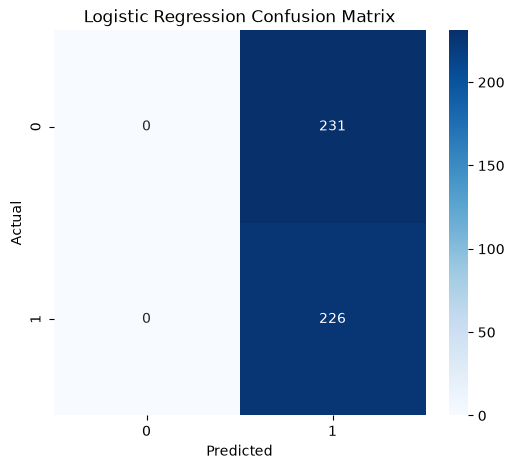

In [14]:
# Logistic Confusion Matrix
cm = confusion_matrix(
    y_test,
    log_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


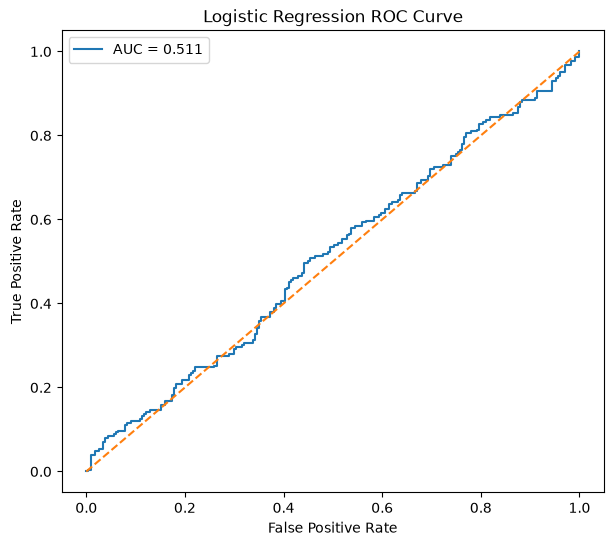

In [15]:
# Logistic ROC Curve
probabilities = (
    log_model
    .predict_proba(X_test)[:,1]
)

fpr, tpr, thresholds = roc_curve(
    y_test,
    probabilities
)

roc_auc = auc(
    fpr,
    tpr
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Logistic Regression ROC Curve"
)

plt.legend()

plt.show()

In [17]:
# Decision Tree
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

tree_pred = tree_model.predict(
    X_test
)

In [18]:
# Decision Tree results
print(
    "Decision Tree Accuracy:",
    accuracy_score(
        y_test,
        tree_pred
    )
)

print(
    classification_report(
        y_test,
        tree_pred
    )
)

Decision Tree Accuracy: 0.5032822757111597
              precision    recall  f1-score   support

           0       0.55      0.09      0.16       231
           1       0.50      0.92      0.65       226

    accuracy                           0.50       457
   macro avg       0.53      0.51      0.40       457
weighted avg       0.53      0.50      0.40       457



In [19]:
# Model Comparison
log_acc = accuracy_score(
    y_test,
    log_pred
)

tree_acc = accuracy_score(
    y_test,
    tree_pred
)

comparison = pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Decision Tree"
    ],

    "Accuracy":[
        log_acc,
        tree_acc
    ]
})

comparison

,Model,Accuracy
0,Logistic Regression,0.494530
1,Decision Tree,0.503282


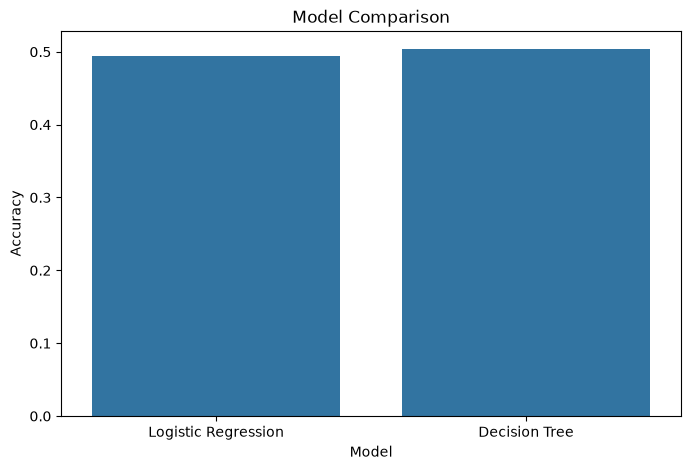

In [20]:
# Bar Chart
plt.figure(figsize=(8,5))

sns.barplot(
    x="Model",
    y="Accuracy",
    data=comparison
)

plt.title(
    "Model Comparison"
)

plt.show()

In [22]:
# error analysis
log_cm = confusion_matrix(
    y_test,
    log_pred
)

tree_cm = confusion_matrix(
    y_test,
    tree_pred
)

print("Logistic Regression Confusion Matrix")
print(log_cm)

print("\nDecision Tree Confusion Matrix")
print(tree_cm)

Logistic Regression Confusion Matrix
[[  0 231]
 [  0 226]]

Decision Tree Confusion Matrix
[[ 21 210]
 [ 17 209]]


In [21]:
print("WEEK 4 SUMMARY")

print("- Built next-day direction prediction models")
print("- Used chronological train/test split")
print("- Avoided look-ahead bias")
print("- Trained Logistic Regression model")
print("- Trained Decision Tree model")
print("- Evaluated models using accuracy")
print("- Generated confusion matrix")
print("- Generated ROC curve")
print("- Compared model performance")

WEEK 4 SUMMARY
- Built next-day direction prediction models
- Used chronological train/test split
- Avoided look-ahead bias
- Trained Logistic Regression model
- Trained Decision Tree model
- Evaluated models using accuracy
- Generated confusion matrix
- Generated ROC curve
- Compared model performance
